# NASCTN CBRS SEA: Aggregate Emission Analysis

This notebook plots and saves aggregate emissions at protection points and sensor locations.

# Disclaimer
This software was developed by employees of the National Institute
of Standards and Technology (NIST), an agency of the Federal
Government. Pursuant to title 17 United States Code Section 105, works
of NIST employees are not subject to copyright protection in the United
States and are considered to be in the public domain. Permission to freely
use, copy, modify, and distribute this software and its documentation
without fee is hereby granted, provided that this notice and disclaimer
of warranty appears in all copies.

THE SOFTWARE IS PROVIDED 'AS IS' WITHOUT ANY WARRANTY OF ANY KIND,
EITHER EXPRESSED, IMPLIED, OR STATUTORY, INCLUDING, BUT NOT LIMITED
TO, ANY WARRANTY THAT THE SOFTWARE WILL CONFORM TO SPECIFICATIONS, ANY
IMPLIED WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE,
AND FREEDOM FROM INFRINGEMENT, AND ANY WARRANTY THAT THE DOCUMENTATION
WILL CONFORM TO THE SOFTWARE, OR ANY WARRANTY THAT THE SOFTWARE WILL BE
ERROR FREE. IN NO EVENT SHALL NIST BE LIABLE FOR ANY DAMAGES, INCLUDING,
BUT NOT LIMITED TO, DIRECT, INDIRECT, SPECIAL OR CONSEQUENTIAL DAMAGES,
ARISING OUT OF, RESULTING FROM, OR IN ANY WAY CONNECTED WITH THIS
SOFTWARE, WHETHER OR NOT BASED UPON WARRANTY, CONTRACT, TORT, OR
OTHERWISE, WHETHER OR NOT INJURY WAS SUSTAINED BY PERSONS OR PROPERTY
OR OTHERWISE, AND WHETHER OR NOT LOSS WAS SUSTAINED FROM, OR AROSE OUT
OF THE RESULTS OF, OR USE OF, THE SOFTWARE OR SERVICES PROVIDED HEREUNDER.

Distributions of NIST software should also include copyright and licensing
statements of any third-party software that are legally bundled with
the code in compliance with the conditions of those licenses.

In [ ]:
import os
import sys
import csv
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Make sure the harness is accessible in the path
sys.path.append(r"../Spectrum-Access-System/src/harness")

# Add 'src' to sys.path
current_dir = Path.cwd()
main_dir = Path(current_dir).parents[0]
src_dir = main_dir / 'src'
sys.path.append(os.path.abspath(src_dir))
import dpa_mgr_SEA as dpa_mgr

In [59]:
# Configuration: DPA name and channels
dpa_name = "West14" # Change as needed (e.g., East1, West13, West14)
channels_start = list(range(3550, 3650, 10))
channels_end = list(range(3560, 3660, 10))
dpa_channels = list(zip(channels_start, channels_end))

# Directories
data_dir = main_dir / 'data'
results_dir = main_dir / 'outputs' / 'results' / dpa_name
plots_dir = main_dir / 'outputs'/ 'plots' / dpa_name
os.makedirs(plots_dir, exist_ok=True)

# DPA protection threshold (-144 dBm / 10 MHz)
prtn_threshold = -144 # dBm/10MHz

## Aggregate Emission at SEA Sensors
Extract aggregate interference computed at SEA sensors, rearrange the data matrices per sensor across all operational channels, and write to CSV files.

In [60]:
sensor_nbr_all = []
sensor_keep_all = []
sensor_glob_all = []
sensor_glob_keep_all = []
valid_channels = []
sensor_objects = None

print("=== Processing Sensor Aggregate Emissions ===")
for f_start, f_end in dpa_channels:
    channel_str = f"channel{f_start}to{f_end}"
    fname = results_dir / f"{dpa_name}_{channel_str}_aggEmission_sensor.npy"
        
    if fname.exists():
        (ch, s_list, em_nbr, em_keep, em_glob, em_glob_keep) = np.load(fname, allow_pickle=True)
        sensor_nbr_all.append(em_nbr)
        sensor_keep_all.append(em_keep)
        sensor_glob_all.append(em_glob)
        sensor_glob_keep_all.append(em_glob_keep)
        valid_channels.append((f_start, f_end))
        if sensor_objects is None:
            sensor_objects = s_list
    else:
        print(f"Sensor emission file missing for {channel_str}.")

if sensor_objects and sensor_nbr_all:
    agg_nbr_arr = np.array(sensor_nbr_all)
    agg_keep_arr = np.array(sensor_keep_all)
    agg_glob_arr = np.array(sensor_glob_all)
    agg_glob_keep_arr = np.array(sensor_glob_keep_all)
    
    sensor_fields = ['channel_frequency_mhz', 'agg_neighbor_list', 'agg_keep_list', 'agg_global_list', 'agg_global_keep_list']
    
    for s_idx, sensor in enumerate(sensor_objects):
        s_name = getattr(sensor, 'sensor_short_name', getattr(sensor, 'name', f'sensor_{s_idx+1}'))
        rows = []
        for k, (f_start, f_end) in enumerate(valid_channels):
            fc_mhz = int((f_start + f_end) / 2)
            rows.append([
                fc_mhz,
                agg_nbr_arr[k, s_idx],
                agg_keep_arr[k, s_idx],
                agg_glob_arr[k, s_idx],
                agg_glob_keep_arr[k, s_idx]
            ])
            
        s_csv_out = results_dir / f"{dpa_name}_aggEmission_{s_name}.csv"
        with open(s_csv_out, 'w', newline="") as f:
            writer = csv.writer(f, quoting=csv.QUOTE_ALL)
            writer.writerow(sensor_fields)
            writer.writerows(rows)
        print(f"Exported sensor CSV: {s_csv_out.name}")
else:
    print("No sensor emission datasets found to process.")

=== Processing Sensor Aggregate Emissions ===
Exported sensor CSV: West14_aggEmission_Catalina-Omni.csv
Exported sensor CSV: West14_aggEmission_Catalina-Directional.csv
Exported sensor CSV: West14_aggEmission_Pendleton.csv
Exported sensor CSV: West14_aggEmission_Midway.csv
Exported sensor CSV: West14_aggEmission_PtLoma-Omni.csv
Exported sensor CSV: West14_aggEmission_PtLoma-Directional.csv


## Aggregate Emission at Protection Points vs. Threshold

In [61]:
prtn_fields = ['Latitude', 'Longitude', 'agg_neighbor_list', 'agg_keep_list', 'agg_global_list', 'agg_global_keep_list']

print("=== Evaluating Protection Point Emissions ===")
for f_start, f_end in dpa_channels:
    channel_str = f"channel{f_start}to{f_end}"
    fname = results_dir / f"{dpa_name}_{channel_str}_aggEmission_prtnPoint.npy"
    if not fname.exists():
        fname = results_dir / f"{dpa_name}_{channel_str}_aggEmission_prtnPoint.npy"
        
    if not fname.exists():
        continue
        
    (channel, protected_points, em_nbr, em_keep, em_glob, em_glob_keep) = np.load(fname, allow_pickle=True)
    
    # Compute maximum emission across radar azimuth scan angles
    max_nbr = [np.amax(a) for a in np.array(em_nbr, dtype=object)]
    max_keep = [np.amax(a) for a in np.array(em_keep, dtype=object)]
    max_glob = [np.amax(a) for a in np.array(em_glob, dtype=object)]
    max_glob_keep = [np.amax(a) for a in np.array(em_glob_keep, dtype=object)]
    
    # Construct CSV rows
    rows = []
    for idx_pt, pt in enumerate(protected_points):
        lat = pt.latitude if hasattr(pt, 'latitude') else pt[0]
        lon = pt.longitude if hasattr(pt, 'longitude') else pt[1]
        rows.append([lat, lon, max_nbr[idx_pt], max_keep[idx_pt], max_glob[idx_pt], max_glob_keep[idx_pt]])
        
    csv_file = results_dir / f"{dpa_name}_{channel_str}_aggEmission_prtnPoint.csv"
    with open(csv_file, 'w', newline="") as f:
        writer = csv.writer(f, quoting=csv.QUOTE_ALL)
        writer.writerow(prtn_fields)
        writer.writerows(rows)
        
    # Plot aggregate emission per protection point
    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=150)
    pt_indices = np.arange(1, len(protected_points) + 1)
    
    ax.plot(pt_indices, max_nbr, 's', markerfacecolor='none', markeredgecolor='#006BA4', label='Neighbor list')
    ax.plot(pt_indices, max_keep, 'o', markerfacecolor='none', markeredgecolor='#FF800E', label='Keep list')
    ax.plot(pt_indices, max_glob, 'x', color='#6A9F58', label='Global list')
    ax.plot(pt_indices, max_glob_keep, '*', color='#A87C9F', label='Global keep list')
    
    ax.axhline(prtn_threshold, color='k', linestyle='--', linewidth=1.2, label=f'Threshold ({prtn_threshold} dBm)')
    
    ax.set_title(f"{dpa_name} Protection Points: {f_start}–{f_end} MHz", fontsize=12)
    ax.set_xlabel("Protection Point Index", fontsize=10)
    ax.set_ylabel("Aggregate Emission (dBm / 10 MHz)", fontsize=10)
    ax.set_ylim(-180, -60)
    ax.set_xlim(0, len(protected_points) + 1)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right', ncol=3, fontsize=8)
    
    plt.tight_layout()
    plot_file = plots_dir / f"{dpa_name}_{channel_str}_aggEmission_prtnPoint.png"
    plt.savefig(plot_file)
    plt.close(fig)
    print(f"Channel {f_start}-{f_end} MHz: Exported CSV and plot ({plot_file.name})")

=== Evaluating Protection Point Emissions ===
Channel 3550-3560 MHz: Exported CSV and plot (West14_channel3550to3560_aggEmission_prtnPoint.png)
Channel 3560-3570 MHz: Exported CSV and plot (West14_channel3560to3570_aggEmission_prtnPoint.png)
Channel 3570-3580 MHz: Exported CSV and plot (West14_channel3570to3580_aggEmission_prtnPoint.png)
Channel 3580-3590 MHz: Exported CSV and plot (West14_channel3580to3590_aggEmission_prtnPoint.png)
Channel 3590-3600 MHz: Exported CSV and plot (West14_channel3590to3600_aggEmission_prtnPoint.png)
Channel 3600-3610 MHz: Exported CSV and plot (West14_channel3600to3610_aggEmission_prtnPoint.png)
Channel 3610-3620 MHz: Exported CSV and plot (West14_channel3610to3620_aggEmission_prtnPoint.png)
Channel 3620-3630 MHz: Exported CSV and plot (West14_channel3620to3630_aggEmission_prtnPoint.png)
Channel 3630-3640 MHz: Exported CSV and plot (West14_channel3630to3640_aggEmission_prtnPoint.png)
Channel 3640-3650 MHz: Exported CSV and plot (West14_channel3640to3650_a

## Spatial Heatmaps of Aggregate Emissions at Protection Points

=== Generating Spatial Heatmaps ===
http://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/export?bbox=-119.76939277088138,30.28734600053164,-116.14538549138612,33.9440366756529&bboxSR=4326&imageSR=4326&size=1500,1513&dpi=300&format=png32&transparent=true&f=image


URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1010)>

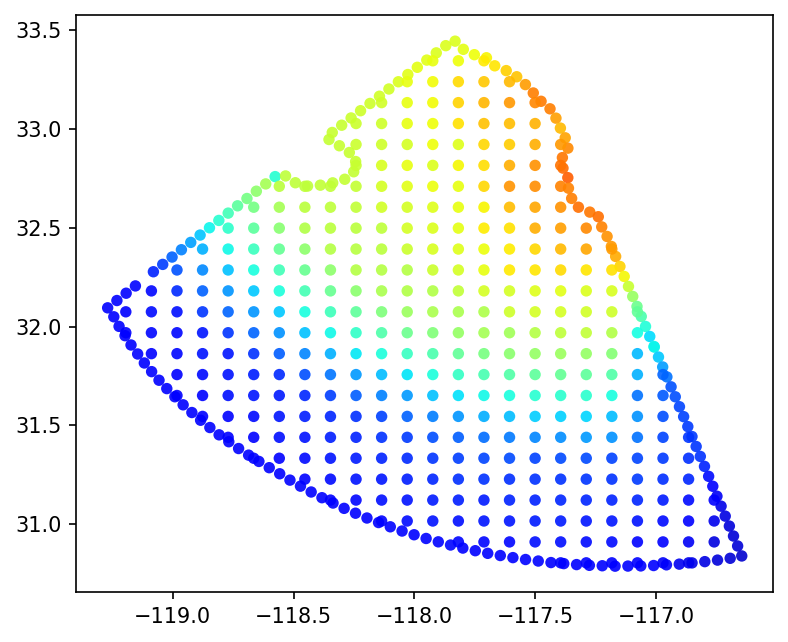

In [ ]:
def plot_spatial_emission_heatmap(latitudes, longitudes, emissions, title_str, save_path):
    """
    Plots spatial aggregate emissions across DPA protection points.
    Preserves geographical distance aspect ratio based on average latitude.
    """
    # Filter out invalid or non-finite coordinates
    valid_mask = np.isfinite(latitudes) & np.isfinite(longitudes) & np.isfinite(emissions)
    if not np.any(valid_mask):
        print(f"Skipping plot for {save_path.name}: No valid data points.")
        return

    lats = np.asarray(latitudes)[valid_mask]
    lons = np.asarray(longitudes)[valid_mask]
    vals = np.asarray(emissions)[valid_mask]

    fig, ax = plt.subplots(figsize=(6, 5), dpi=150)
    
    sc = ax.scatter(
        lons, lats,
        c=vals,
        cmap='jet',
        s=30,
        vmin=-180,
        vmax=-60,
        edgecolors='none',
        alpha=0.9
    )

    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Aggregate Emission (dBm / 10 MHz)", fontsize=10)
    
    ax.set_title(title_str, fontsize=11, pad=10)
    ax.set_xlabel("Longitude (°)", fontsize=10)
    ax.set_ylabel("Latitude (°)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # Calculate Mercator/equirectangular aspect correction safely
    mean_lat = np.mean(lats)
    cos_lat = np.cos(np.radians(mean_lat))
    if np.isfinite(cos_lat) and cos_lat > 0:
        ax.set_aspect(1.0 / cos_lat)
    else:
        ax.set_aspect('equal')
        
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.close(fig)

# --- CSV Parsing Loop ---
print("=== Generating Spatial Heatmaps ===")
list_types = [
    ("Neighbor List", "agg_neighbor_list"),
    ("Keep List", "agg_keep_list"),
    ("Global List", "agg_global_list"),
    ("Global Keep List", "agg_global_keep_list")
]

for f_start, f_end in dpa_channels:
    channel_str = f"channel{f_start}to{f_end}"
    channel_txt = f"{f_start}–{f_end} MHz"
    csv_file = results_dir / f"{dpa_name}_{channel_str}_aggEmission_prtnPoint.csv"
        
    if not csv_file.exists():
        continue
        
    # Read CSV via pandas to parse quoted numeric fields seamlessly
    df_prtn = pd.read_csv(csv_file)
    if df_prtn.empty:
        continue
        
    lats = df_prtn['Latitude'].to_numpy(dtype=float)
    lons = df_prtn['Longitude'].to_numpy(dtype=float)
    
    for list_name, col_name in list_types:
        if col_name not in df_prtn.columns:
            continue
        emissions = df_prtn[col_name].to_numpy(dtype=float)
        clean_name = list_name.replace(" ", "")
        title = f"{dpa_name} ({channel_txt})\nAggregate Emission: {list_name}"
        out_png = plots_dir / f"{dpa_name}_{channel_str}_aggEmission_prtnPoint_heatmap_{clean_name}.png"
        
        plot_spatial_emission_heatmap(lats, lons, emissions, title, out_png)
        print(f"Generated heatmap: {out_png.name}")